In [118]:
from torch_geometric.datasets import QM9
ds = QM9(root="data/QM9")
print(len(ds))
print(ds[0])

130831
Data(x=[5, 11], edge_index=[2, 8], edge_attr=[8, 4], y=[1, 19], pos=[5, 3], idx=[1], name='gdb_1', z=[5])


In [119]:
import numpy as np, matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_absolute_error

max atoms: 29 | mean: 18.0


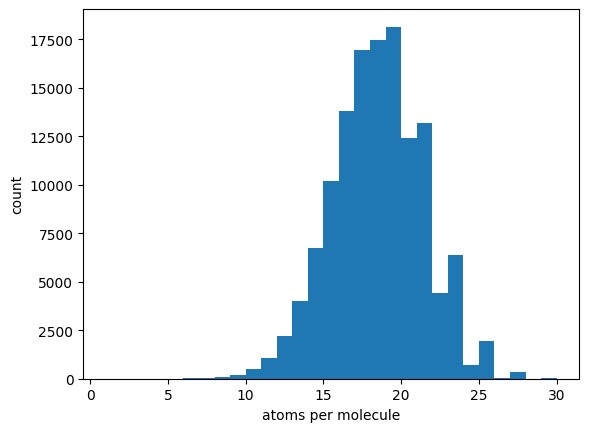

{np.int64(1): np.int64(1208486), np.int64(6): np.int64(831925), np.int64(7): np.int64(132498), np.int64(8): np.int64(183265), np.int64(9): np.int64(3036)}


In [120]:


sl = ds.slices['z']
n_atoms = (sl[1:] - sl[:-1]).numpy()          # atoms per molecule, all 130k
print("max atoms:", n_atoms.max(), "| mean:", n_atoms.mean().round(1))

plt.hist(n_atoms, bins=range(1, 31))
plt.xlabel("atoms per molecule"); plt.ylabel("count"); plt.show()

elems, counts = np.unique(ds._data.z.numpy(), return_counts=True)
print(dict(zip(elems,counts))     )          # 1=H, 6=C, 7=N, 8=O, 9=F

mean: -1755.3 | std: 238.1
MAE of always predicting the mean: 187.3


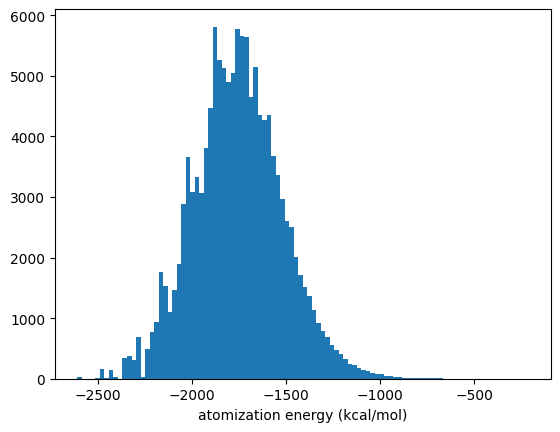

In [121]:
EV_TO_KCAL = 23.0605
y = np.array(ds._data.y[:, 12].numpy(),float) * EV_TO_KCAL    # atomization energy, kcal/mol
print("mean:", y.mean().round(1), "| std:", y.std().round(1))
print("MAE of always predicting the mean:", np.abs(y - y.mean()).mean().round(1))

plt.hist(y, bins=100)
plt.xlabel("atomization energy (kcal/mol)"); plt.show()

In [122]:

d = ds[0]                                      # methane
print(d.z)
print(torch.cdist(d.pos, d.pos).round(decimals=2))

tensor([6, 1, 1, 1, 1])
tensor([[0.0000, 1.0900, 1.0900, 1.0900, 1.0900],
        [1.0900, 0.0000, 1.7800, 1.7800, 1.7800],
        [1.0900, 1.7800, 0.0000, 1.7800, 1.7800],
        [1.0900, 1.7800, 1.7800, 0.0000, 1.7800],
        [1.0900, 1.7800, 1.7800, 1.7800, 0.0000]])


In [123]:
rng = np.random.default_rng(0)  # fixed seed for reproducibility
idx = rng.choice(len(ds),6000,replace=False)
Z,POS = ds._data.z.numpy(),ds._data.pos.numpy()
# Puts molecules in one long array like[6 1 1 1 1 | 8 1 1 | 6 6 1 1]
S = ds.slices["z"].numpy()
# molecule i is z[S[i]:S[i+1]]
MAX_ATOMS = 29  # largest molecule in QM9, pad everything to this
def build_coulomb_matrix(z,p,nmax = MAX_ATOMS):
    """Sorted, zero-padded Coulomb matrix, upper triangle only.Returns length nmax*(nmax+1)/2 = 435."""
    n = len(z)
    pairwise_d = np.sqrt(np.sum((p[:,None,:]-p[None,:,:])**2,axis=2))   # distance matrix
    pairwise_z = z[:,None]*z[None,:]
    np.fill_diagonal(pairwise_d,1.0)     # avoid divide-by-zero on the diagonal
    coulomb_matrix = pairwise_z/pairwise_d
    np.fill_diagonal(coulomb_matrix,0.5*z**2.4) # self-interaction term
    padded = np.zeros((nmax,nmax))
    padded[:n,:n] = coulomb_matrix
    row_lengths = np.linalg.norm(padded,axis=1)
    order = np.argsort(-row_lengths)    # sort by row norm so the features are permutation-invariant
    P = padded[order][:,order]
    return P[np.triu_indices(nmax)] # matrix is symmetric, so keep the upper triangle only
X = np.array([build_coulomb_matrix(Z[S[i]:S[i+1]], POS[S[i]:S[i+1]]) for i in idx])
y = ds._data.y[idx, 12].numpy() * 23.0605   # eV -> kcal/mol
# ------Build atom count baseline-------
X_base = np.array([[(Z[S[i]:S[i+1]]==k).sum() for k in [1,6,7,8,9]] for i in idx])  # counts of H, C, N, O, F per molecule
print(X_base.shape, X_base[:3])                     # expect (6000, 5)
print(np.array_equal(X_base.sum(axis=1), np.diff(S)[idx]))   # expect True   

(6000, 5) [[12  9  0  0  0]
 [ 8  6  2  1  0]
 [ 7  7  1  1  0]]
True


In [124]:
np.savez("features.npz", X=X, X_base=X_base, y=y, idx=idx)
print(np.load("features.npz").files)    # ['X', 'X_base', 'y', 'idx']

['X', 'X_base', 'y', 'idx']


In [125]:

all_pos = np.arange(len(y))
pool_pos,test_pos = train_test_split(all_pos,test_size=1000,random_state=0)
X_test,  Xb_test,  y_test  = X[test_pos],  X_base[test_pos],  y[test_pos]
X_pool,  Xb_pool,  y_pool  = X[pool_pos],  X_base[pool_pos],  y[pool_pos]
def train_func(num_train):
    """Take the first num_train molecules from the pool and tune KRR hyperparameters
    for both feature sets. Returns the training data and best params for each."""
    # Slicing the same shuffled pool means smaller training sets are nested
    # inside larger ones, which keeps the learning curve smooth
    X_train,Xb_train,y_train = X_pool[:num_train],Xb_pool[:num_train],y_pool[:num_train]
    # Coulomb matrix features: grid over regularization (alpha) and kernel width (gamma)
    grid1 = {"alpha":[ 1e-9,1e-8,1e-7,1e-6,1e-5,1e-4],
        "gamma": [1e-8,1e-7,1e-6,1e-5,1e-4,1e-3]}
    gs1 = GridSearchCV(KernelRidge(kernel="laplacian"), grid1,
                  scoring="neg_mean_absolute_error", cv=3)
    # Subtract the mean since KRR has no intercept (add it back when predicting)
    gs1.fit(X_train[:num_train], y_train[:num_train] - y_train.mean())
    # Atom-count baseline: gamma range is shifted up because these features
    # are small integer counts, so the kernel needs a different length scale
    grid2 = {"alpha": [1e-8,1e-7,1e-6,1e-5,1e-4],
        "gamma": [1e-6,1e-5,1e-4,1e-3,1e-2,1e-1]}
    gs2 = GridSearchCV(KernelRidge(kernel="laplacian"), grid2,
                  scoring="neg_mean_absolute_error", cv=3)
    gs2.fit(Xb_train[:num_train], y_train[:num_train] - y_train.mean())
    return X_train,Xb_train,y_train,gs1.best_params_,gs2.best_params_

In [126]:
# Learning curve: test MAE vs. training set size, for Coulomb matrix and atom-count features
# Takes ~5 minutes, grid search dominates
Ns = [100,250,500,1000,2000,5000]   # training set sizes
alphas_coulomb = []
gammas_coulomb = []
alphas_b = []
gammas_b = []
# Test MAE at each N
MAE_coulomb_list = []
MAE_baseline_list = []
for n in Ns:
    # Grid search on the first n pool molecules (CV happens inside train_func)
    X_train,Xb_train,y_train,dict_params_coulomb,dict_params_b = train_func(n)
    # Record the chosen hyperparameters
    alpha_coulomb = dict_params_coulomb["alpha"]
    alphas_coulomb.append(alpha_coulomb)
    gamma_coulomb = dict_params_coulomb["gamma"]
    gammas_coulomb.append(gamma_coulomb)
    alpha_b = dict_params_b["alpha"]
    alphas_b.append(alpha_b)
    gamma_b = dict_params_b["gamma"]
    gammas_b.append(gamma_b)
    # KRR has no intercept, so center the targets on the training mean
    y_mean = y_train.mean()
    # Coulomb matrix model
    model_coulomb = KernelRidge(kernel="laplacian", alpha=alpha_coulomb, gamma=gamma_coulomb)
    model_coulomb.fit(X_train, y_train - y_mean)        # learn from the training set only
    pred_coulomb = model_coulomb.predict(X_test) + y_mean       # predict on unseen molecules, add the mean back
    MAE_coulomb_list.append(mean_absolute_error(y_test, pred_coulomb))
    # Atom-count baseline model (same pipeline, simpler features)
    model_b = KernelRidge(kernel="laplacian", alpha=alpha_b, gamma=gamma_b)
    model_b.fit(Xb_train, y_train - y_mean)        # learn from the training set only
    pred_b = model_b.predict(Xb_test) + y_mean       # predict on unseen molecules, add the mean back
    MAE_baseline_list.append(mean_absolute_error(y_test, pred_b))
# Chosen hyperparameters per N
print(f"alphas_coulomb:{alphas_coulomb}")
print(f"gammas_coulomb:{gammas_coulomb}")
print(f"alphas_baseline:{alphas_b}")
print(f"gammas_baseline:{gammas_b}")
# Test MAE per N 
print(f"List of coulomb MAEs:{MAE_coulomb_list}")
print(f"List of atom count baseline MAEs:{MAE_baseline_list}")
# Reference: MAE of always predicting the training mean
print(f"Predict the mean MAE:{np.abs(y_test-y_mean).mean():.4f}")

alphas_coulomb:[1e-09, 1e-09, 1e-09, 1e-09, 1e-05, 0.0001]
gammas_coulomb:[1e-07, 1e-07, 0.0001, 0.0001, 0.0001, 0.0001]
alphas_baseline:[0.0001, 1e-08, 1e-07, 1e-07, 1e-07, 0.0001]
gammas_baseline:[0.001, 1e-05, 1e-06, 1e-06, 1e-05, 0.001]
List of coulomb MAEs:[33.611757671900094, 22.62635092568211, 18.028518685911774, 12.921419776962074, 10.076667437605108, 7.651042456182651]
List of atom count baseline MAEs:[28.739159660003615, 21.878256240844728, 20.68737512886524, 20.34796313416958, 19.80254637670517, 19.710653382783757]
Predict the mean MAE:189.5075


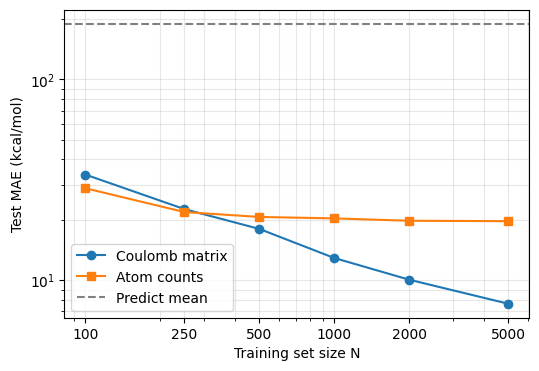

learning-curve slope: -0.38


In [127]:
# Learning Curve
plt.figure(figsize=(6,4))
plt.loglog(Ns, MAE_coulomb_list, "o-", label="Coulomb matrix")
plt.loglog(Ns, MAE_baseline_list, "s-", label="Atom counts")
plt.axhline(np.abs(y_test - y_mean).mean(), color="gray", ls="--", label="Predict mean")
plt.xlabel("Training set size N"); plt.ylabel("Test MAE (kcal/mol)")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
from matplotlib.ticker import ScalarFormatter
ax = plt.gca()
ax.set_xticks(Ns); ax.set_xticklabels(Ns)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
plt.savefig("learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

# slope of the Coulomb curve on log-log axes
slope = np.polyfit(np.log(Ns), np.log(MAE_coulomb_list), 1)[0]
print("learning-curve slope:", round(slope, 2))

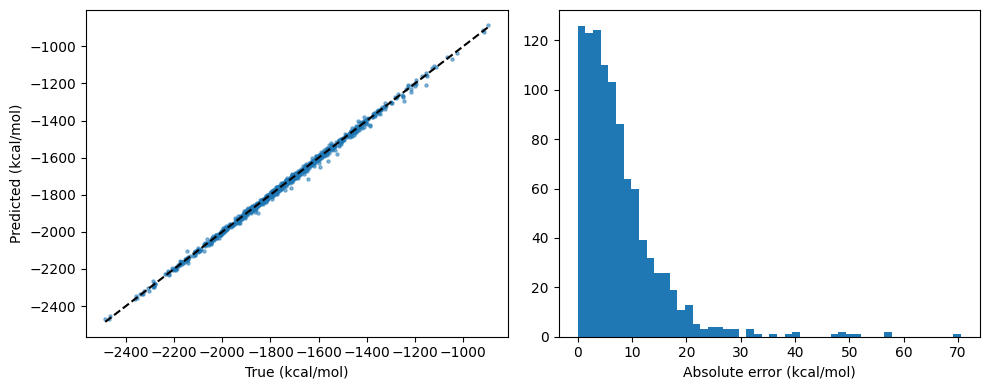

err=70.5  atoms=18  composition(H,C,N,O,F)=[9 5 3 1 0]
err=57.4  atoms=16  composition(H,C,N,O,F)=[7 6 1 2 0]
err=56.5  atoms=16  composition(H,C,N,O,F)=[7 6 1 2 0]
err=51.9  atoms=16  composition(H,C,N,O,F)=[7 7 1 1 0]
err=50.3  atoms=11  composition(H,C,N,O,F)=[2 3 2 4 0]
err=48.1  atoms=19  composition(H,C,N,O,F)=[10  8  0  1  0]
err=48.0  atoms=12  composition(H,C,N,O,F)=[3 4 2 2 1]
err=47.9  atoms=18  composition(H,C,N,O,F)=[9 7 1 1 0]
err=40.1  atoms=21  composition(H,C,N,O,F)=[12  9  0  0  0]
err=39.8  atoms=14  composition(H,C,N,O,F)=[5 4 3 2 0]
mean atoms, all test: 18.1 | mean atoms, worst 10: 16.1


In [128]:
err = np.abs(y_test - pred_coulomb)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(y_test, pred_coulomb, s=5, alpha=0.5)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "k--")
ax[0].set_xlabel("True (kcal/mol)"); ax[0].set_ylabel("Predicted (kcal/mol)")
ax[1].hist(err, bins=50)
ax[1].set_xlabel("Absolute error (kcal/mol)")
plt.tight_layout()
plt.savefig("error_analysis.png", dpi=200, bbox_inches="tight")
plt.show()

# worst 10 molecules
worst = np.argsort(-err)[:10]
n_atoms_test = np.diff(S)[idx[test_pos]]
for j in worst:
    print(f"err={err[j]:.1f}  atoms={n_atoms_test[j]}  composition(H,C,N,O,F)={Xb_test[j]}")
print("mean atoms, all test:", n_atoms_test.mean().round(1),
      "| mean atoms, worst 10:", n_atoms_test[worst].mean().round(1))